In [1]:
# Install standard python libraries
import time as t
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

In [2]:
# Load weather and electricity data
filename1 = 'Data_Tallinn_Casestudy.xlsx'
Table_data = pd.read_excel(filename1)

Tair = Table_data.iloc[:, 1].values  # air temp [ºC]
P = Table_data.iloc[:, 2].values  # Total Rain [mm]
D = Table_data.iloc[:, 3].values  # Cooling load [kW]
E = Table_data.iloc[:, 4].values  # Ele cost [EUR]
s = Tair.shape # timestamp of data i.e 8760
P[np.isnan(P)] = 0

print('\t Input data loaded successfully')

	 Input data loaded successfully


# Snow Storage Unit

In [3]:
def Geometry(Prop):
    a, b, alpha, beta, d, h = Prop[:6]

    # Precompute common terms
    tan_beta = np.tan(beta)
    tan_alpha = np.tan(alpha)
    sin_beta = np.sin(beta)
    sin_alpha = np.sin(alpha)

    # Volume calculations
    term_surf = (a - 2.0 * h / tan_beta) * (b - 2.0 * h / tan_beta)
    sqrt_surf = np.sqrt((a * b) * term_surf)
    Vol_surf = (h / 3.0) * ((a * b) + term_surf + sqrt_surf)

    term_below = (a - 2.0 * d / tan_alpha) * (b - 2.0 * d / tan_alpha)
    sqrt_below = np.sqrt((a * b) * term_below)
    Vol_below = (d / 3.0) * ((a * b) + term_below + sqrt_below)

    Vol_tot = Vol_below + Vol_surf

    # Area calculations
    a_surf = term_surf + (h / sin_beta) * (2.0 * a + 2.0 * b + 2.0 * \
            (a - 2.0 * h / tan_beta) + 2.0 * (b - 2.0 * h / tan_beta)) / 2.0
    a_below = term_below + (d / sin_alpha) * ((2.0 * a + 2.0 * b) + \
            2.0 * (a - 2.0 * d / tan_alpha) + 2.0 * (b - 2.0 * d / tan_alpha)) / 2.0

    return [Vol_surf, Vol_below, Vol_tot, a_surf, a_below]


In [4]:
def Melted_Volume(Temp, Rain, CDD, Prop, hour):
    a, b, alpha, beta, d, h, Dw, Ds, Ls, cw, lambda_i, lambda_g, thickness = Prop

    # Precompute common terms
    tan_beta = np.tan(beta)
    tan_alpha = np.tan(alpha)
    sin_beta = np.sin(beta)
    sin_alpha = np.sin(alpha)

    # Surface area
    if h > 0:
        A = (a - 2.0 * h / tan_beta) * (b - 2.0 * h / tan_beta) + (h / sin_beta) * \
            (2.0 * a + 2.0 * b + 2.0 * (a - 2.0 * h / tan_beta) + 2.0 * (b - 2.0 * h / tan_beta)) / 2.0
    else:
        A = (a - 2.0 * abs(h) / tan_alpha) * (b - 2.0 * abs(h) / tan_alpha)

    # Ground area
    Ag = (a - 2.0 * d / tan_alpha) * (b - 2.0 * d / tan_alpha) + (d / sin_alpha) * \
        ((2.0 * a + 2.0 * b) + 2.0 * (a - 2.0 * d / tan_alpha) + 2.0 * (b - 2.0 * d / tan_alpha)) / 2.0

    # Surface melt
    Q_surf = A * (lambda_i / thickness) * Temp if Temp > 0 else 0
    V_surf = (Q_surf / (Ls * Ds)) * 3600.0

    # Rain melt
    V_rain = ((Rain / 1000.0) * A * Dw * cw * Temp) / (Ls * Ds) if Temp > 0 else 0

    # Ground melt
    Q_ground = lambda_g * Ag * 2.0
    V_ground = (Q_ground / (Ls * Ds)) * 3600.0

    # Forced snow melt (with cooling)
    if hour > (2280) and hour < (6480):
      V_cool = Cool*3.6*10**6/(Ls * Ds)
    else:
      V_cool = 0

    # Total snowmelt
    V_melt = V_surf + V_rain + V_ground + V_cool
    V_melt0 = V_surf + V_rain + V_ground

    return V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool

In [5]:
def findHeightNew(V, Prop):
    a = Prop[0]
    b = Prop[1]
    alpha = Prop[2]
    beta = Prop[3]
    d = Prop[4]

    Vol_below = (d / 3.0) * ((a * b) + (a - 2.0 * d / np.tan(alpha)) * (b - 2.0 * d / np.tan(alpha)) \
                + np.sqrt((a * b) * (a - 2.0 * d / np.tan(alpha)) * (b - 2.0 * d / np.tan(alpha))))

    if V > Vol_below:
        h_new = calcHeight(V, Vol_below, a, b, beta)
    else:
        h_new = -calcHeight(Vol_below - V, 0, a, b, alpha)

    return h_new

In [6]:
def calcHeight(V, V_offset, a, b, angle):
    h_max = np.tan(angle) * (a / 2) * 50.0

    Vol_matrix = np.array([(i / 100.0 / 3.0) * ((a * b) + (a - 2.0 * i / 100.0 / np.tan(angle)) * \
        (b - 2.0 * i / 100.0 / np.tan(angle)) + np.sqrt((a * b) * (a - 2.0 * i / 100.0 / np.tan(angle)) *\
        (b - 2.0 * i / 100.0 / np.tan(angle)))) for i in range(1, int(h_max) + 1)])

    k = np.polyfit(Vol_matrix, np.arange(1, int(h_max) + 1), 1)
    h = k[0] * (V - V_offset) / 100.0

    return h

# Design and Sizing

In [7]:
################# Snow Storage Unit #######################
a = 40.0  # Short side [m]
b = 70.0  # Long side [m]
alpha_degrees = 45.0  # Slope angle below surface
beta_degrees = 30.0  # Slope angle above surface
d = 2.0  # Pit depth [m]
h = 4.0  # Pile height [m]
beta = beta_degrees * np.pi / 180.0  # [rad]
alpha = alpha_degrees * np.pi / 180.0  # [rad]
Dw = 1000.0  # Density of water [kg m-3]
Ds = 750.0  # Density of snow [kg m-3]
Ls = 334000.0  # Latent heat of fusion [J kg-1]
cw = 4185.0  # Heat capacity [J kg-1 K-1]
lambda_i = 0.1  # Sawdust thermal conductivity [W m-1 K-1]
lambda_g = 1.0  # Ground thermal conductivity [W m-1 K-1]
thickness = 0.1  # Insulation layer thickness
Prop = [a, b, alpha, beta, d, h, Dw, Ds, Ls, cw, lambda_i, lambda_g, thickness]
Prop0 = Prop.copy()
Prop0 = Prop.copy()

# Calculate initial values
Geo = Geometry(Prop)
Vi = Geo[0] + Geo[1]   # Initial volume of snow
Vi0 = Geo[0] + Geo[1]  # Record initial value
Vf = np.zeros(6)
mass = Vi * Ds

# for simulation loop
dis_cap_snow = max(D)
Es = 0.0926 # enthalpy of fusion [kWh/kg]
cv_storedSnow =  Ds * Es # kWh/m3

print(f"\n inital volume of snow: {Vi0:.2f} m3 ")
print(f"\n initial mass of snow: {mass:.2f} kg \n")
print(f" discharge capacity: {dis_cap_snow:.2f} kW")



 inital volume of snow: 13563.62 m3 

 initial mass of snow: 10172717.18 kg 

 discharge capacity: 941.70 kW


In [8]:
################## ELECTRIC CHILLER ################################
T_ChillerEvap = 280  # temperature in Kelvin
T_ChillerCond = 308  # temperature in Kelvin
deltaT_chiller = T_ChillerCond - T_ChillerEvap

# Calculating COP value based on Carnot value (45-55%)
COP_Carnot = T_ChillerEvap/deltaT_chiller
COP_Chiller = COP_Carnot * 0.55

# Assume chiller capacity is 80% of peak cooling power
chiller_cap = max(D)*0.80

print(f"\n Electric Chiller ")
print(f"  Carnot COP: {COP_Carnot} unitless")
print(f"  Actual COP: {COP_Chiller} unitless")
print(f"  Chiller capacity: {chiller_cap:.2f} kW")


 Electric Chiller 
  Carnot COP: 10.0 unitless
  Actual COP: 5.5 unitless
  Chiller capacity: 753.36 kW


In [9]:
#########################Chilled Water Tank####################

T_CWT_high = 17
T_CWT_low = 4
deltaT_tank = T_CWT_high - T_CWT_low
rho_water = 999   # kg/m^3 (density at 10C)
cp_water = 4.184  # kJ/kg.K

# calculating tank energy capacity (kJ)
cool_high= np.max(D) * 0.8
time_high = np.sum(D > cool_high)
enrg_autm = time_high
enrg_stored = np.mean(D) * enrg_autm * 3600

# calculating tank parameters
tank_mass = enrg_stored / (cp_water * deltaT_tank)
tank_vol = (tank_mass / rho_water) * 1.25 # safety factor
tank_cap = (tank_vol * rho_water * cp_water * deltaT_tank) / 3600
dis_cap_tank = tank_cap/enrg_autm
chrg_cap_tank = tank_cap/enrg_autm

print(f"\n Chilled Water Tank ")
print(f"   Desired Autonomy:   {enrg_autm} Hours")
print(f"   Required Energy:    {enrg_stored:.2f} KJ")
print(f"   Design Volume:      {tank_vol:.2f} m^3")
print(f"   Tank Capacity:      {tank_cap:.2f} kWh")
print(f"   Charge/Discharge Capacity: {dis_cap_tank:.2f} kW")


 Chilled Water Tank 
   Desired Autonomy:   105 Hours
   Required Energy:    73945928.29 KJ
   Design Volume:      1701.08 m^3
   Tank Capacity:      25675.67 kWh
   Charge/Discharge Capacity: 244.53 kW


# Main Simulation Loop

In [10]:
######## Estimation of hourly snowmelt volume with forced cooling ###########

num_of_hrs = s[0]
Vf2 = np.zeros((len(Vf), num_of_hrs))
Vnew2 = np.zeros(num_of_hrs)
storeh = np.zeros(num_of_hrs)

for i in range(s[0]):
    Temp = Tair[i]
    Rain = P[i]
    Cool = D[i]
    hour = i + 1

    V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool = Melted_Volume(Temp, Rain, Cool, Prop, hour)

    Vf2[:, i] = [V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool]

    current_Vi = Vi - Vf2[0, i]

    if current_Vi <= 0:
        Vi = 0
        h_new = 0
    else:
        Vi = current_Vi
        h_new = findHeightNew(Vi, Prop)

    Vnew2[i] = Vi
    storeh[i] = h_new

    Prop[5] = h_new

######## Estimation of hourly snowmelt volume natural cooling ###########

Vf0 = np.zeros((len(Vf), num_of_hrs))
Vnew0 = np.zeros(num_of_hrs)
storeh0 = np.zeros(num_of_hrs)

for i in range(s[0]):
    Temp = Tair[i]
    Rain = P[i]
    hour = i + 1

    V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool = Melted_Volume(Temp, Rain, 0, Prop0, hour)

    Vf0[:, i] = [V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool]

    current_Vi0 = Vi0 - Vf0[1, i]

    if current_Vi0 <= 0:
        Vi0 = 0
        h_new0 = 0
    else:
        Vi0 = current_Vi0
        h_new0 = findHeightNew(Vi0, Prop0)

    Vnew0[i] = Vi0
    storeh0[i] = h_new0
    Prop0[5] = h_new0

# Extracting results
pit_variations_df = pd.DataFrame({
    'Day': np.arange(1, num_of_hrs + 1),
    'PitHeight_WC': storeh,
    'PitVol_WC': Vnew2,
    'PitHeight_WoC': storeh0,
    'PitVol_WoC': Vnew0
})

output_filename1 = 'pit_variations.xlsx'
pit_variations_df.to_excel(output_filename1, index=False)

heat_leakage_df = pd.DataFrame({
    'Day': np.arange(1, num_of_hrs + 1),
    'SurfaceMelt_WC': Vf2[2,:],
    'RainMelt_WC': Vf2[3,:],
    'GroundMelt_WC': Vf2[4,:],
    'SupplyMelt_WC': Vf2[5,:]
})

output_filename2 = 'heat_leakage.xlsx'
heat_leakage_df.to_excel(output_filename2, index=False)


In [11]:
pitVol_zero = -1
for idx, val in enumerate(Vnew2):
    if val <= 0:
        pitVol_zero = idx + 1  # +1 because idx is 0-based and day is 1-based
        break

if pitVol_zero != -1:
   print(f"pit volume became zero/negative on hour: {pitVol_zero}")
else:
   print("pit volume never became zero")

pit volume became zero/negative on hour: 5009


In [15]:
# initialise variables
avg_ele_price = np.mean(E)/1000
lowP_thd = avg_ele_price * 0.75  # 25% below average
highP_thd = avg_ele_price * 1.25  # 25% above average
tank_energy = 0  # starting energy content in the tank

# Arrays to store cooling contribution
snow_used = np.zeros(num_of_hrs)
tank_discharge = np.zeros(num_of_hrs)
tank_level = np.zeros(num_of_hrs)
chiller_2load = np.zeros(num_of_hrs)
chiller_2tank = np.zeros(num_of_hrs)
chiller_eleprice = np.zeros(num_of_hrs)
air_cooling = np.zeros(num_of_hrs)
load_unmet = np.zeros(num_of_hrs)

for i in range(num_of_hrs):

    T_air = Tair[i]

    if (T_air < 5):
        air_cooling[i] = D[i]
        actual_coolD = 0
    else:
        actual_coolD = D[i]

    ele_price = E[i]/1000
    remaining_demand = actual_coolD
    av_snowcoolg = Vnew2[i] * cv_storedSnow

    # initial daily contributions for current hour
    current_snow_used = 0
    current_tank_dis = 0
    current_chiller_2load = 0
    current_chiller_2tank = 0
    current_chiller_elep = 0

    # Prioritize snow storage supply as and when its available
    if (i >= (120*24) and i < pitVol_zero - 1):
        snow_to_meet_demand = min(remaining_demand, dis_cap_snow, av_snowcoolg)
        current_snow_used = snow_to_meet_demand
        remaining_demand -= current_snow_used

    # Cold dispatch based on electricity price
    if ele_price > highP_thd:
        if remaining_demand > 0:
            tank_dis_amt = min(remaining_demand, tank_energy, dis_cap_tank)
            current_tank_dis += tank_dis_amt
            tank_energy -= tank_dis_amt
            remaining_demand -= tank_dis_amt

        if remaining_demand > 0:
            chiller_amt = min(remaining_demand, chiller_cap)
            current_chiller_2load += chiller_amt
            current_chiller_elep += chiller_amt / COP_Chiller * ele_price
            remaining_demand -= chiller_amt

    elif ele_price < lowP_thd:
        if remaining_demand > 0:
            tank_dis_amt = min(remaining_demand, tank_energy, dis_cap_tank)
            current_tank_dis += tank_dis_amt
            tank_energy -= tank_dis_amt
            remaining_demand -= tank_dis_amt

        if remaining_demand > 0:
            chiller_amt = min(remaining_demand, chiller_cap)
            current_chiller_2load += chiller_amt
            current_chiller_elep += chiller_amt / COP_Chiller * ele_price
            remaining_demand -= chiller_amt

        av_tank_space = tank_cap - tank_energy
        av_chiller_4chrg = chiller_cap - current_chiller_2load

        if av_tank_space > 0 and av_chiller_4chrg > 0:
            charge_amount = min(av_tank_space, av_chiller_4chrg, chrg_cap_tank)
            current_chiller_2tank += charge_amount
            tank_energy += charge_amount
            current_chiller_elep += charge_amount / COP_Chiller * ele_price

    else:
        if remaining_demand > 0:
            tank_dis_amt = min(remaining_demand, tank_energy, dis_cap_tank)
            current_tank_dis += tank_dis_amt
            tank_energy -= tank_dis_amt
            remaining_demand -= tank_dis_amt

        if remaining_demand > 0:
            chiller_amt = min(remaining_demand, chiller_cap)
            current_chiller_2load += chiller_amt
            current_chiller_elep += chiller_amt / COP_Chiller * ele_price
            remaining_demand -= chiller_amt

    # Updating array each hour
    snow_used[i] = current_snow_used
    tank_discharge[i] = current_tank_dis
    tank_level[i] = tank_energy
    chiller_2load[i] = current_chiller_2load
    chiller_2tank[i] = current_chiller_2tank
    chiller_eleprice[i] = current_chiller_elep
    load_unmet[i] = max(0, remaining_demand)

# Total contribution from each source (MWh) and total cost
snow_share = np.sum(snow_used) / 1000
tank_share = np.sum(tank_discharge) / 1000
chiller_share = np.sum(chiller_2load) / 1000
tot_chiller_tankchrg = np.sum(chiller_2tank) / 1000
tot_chiller_eleprice = np.sum(chiller_eleprice)
tot_load_unmet = np.sum(load_unmet) / 1000
tot_air_cooling = np.sum(air_cooling) / 1000

# Extracting energy balance results
coldsupply_allocations_df = pd.DataFrame({
     'Hour': np.arange(1, num_of_hrs + 1),
     'Cooling_Demand': D,
     'Snow_Used': snow_used,
     'Tank_Discharge': tank_discharge,
     'Chiller_Direct_Load': chiller_2load,
     'Chiller_Tank_Charge': chiller_2tank,
     'Tank_Level_End_of_Hour': tank_level,
     'Chiller_Electricity_Cost': chiller_eleprice,
     'Load_Unmet': load_unmet,
     'Air_Cooling': air_cooling,
     'Electricity_Price': E
 })

output_filename3 = 'coldsupply_allocations.xlsx'
coldsupply_allocations_df.to_excel(output_filename3, index=False)
print(f"\nHourly cooling contributions exported to '{output_filename3}'")

# Overview of results
print(f"\n Energy Balance Analysis with rule-based dispatch")
print(f"\t Snow contribution (MWh): {snow_share:.2f}")
print(f"\t Tank discharge to load (MWh): {tank_share:.2f}")
print(f"\t Chiller to load (MWh): {chiller_share:.2f}")
print(f"\t Chiller to tank charge thermal (MWh): {tot_chiller_tankchrg:.2f}")
print(f"\t Chiller electricity cost (EUR): {tot_chiller_eleprice:.2f}")
print(f"\t Air cooling (MWh): {tot_air_cooling:.2f}")
print(f"\t Load unmet (MWh): {tot_load_unmet:.2f}")

# Cross-Checks
print(f"\n snow storage - maximum value of cold supply per hour: {max(snow_used):.2f} kW")
print(f" chiller - maximum value of cold production per hour: {max(chiller_2load):.2f} kW")
print(f" tank - maximum value of cold discharge: {max(tank_discharge):.2f} kW")
print(f" tank - maximum value of charging: {max(chiller_2tank):.2f} kW")
print(f" tank - maximum value of energy level: {max(tank_level):.2f} kWh")


Hourly cooling contributions exported to 'coldsupply_allocations.xlsx'

 Energy Balance Analysis with rule-based dispatch
	 Snow contribution (MWh): 661.36
	 Tank discharge to load (MWh): 351.59
	 Chiller to load (MWh): 188.12
	 Chiller to tank charge thermal (MWh): 377.27
	 Chiller electricity cost (EUR): 4332.10
	 Air cooling (MWh): 511.88
	 Load unmet (MWh): 0.72

 snow storage - maximum value of cold supply per hour: 941.70 kW
 chiller - maximum value of cold production per hour: 753.36 kW
 tank - maximum value of cold discharge: 244.53 kW
 tank - maximum value of charging: 244.53 kW
 tank - maximum value of energy level: 25675.67 kWh


# Graphical Results

Component level

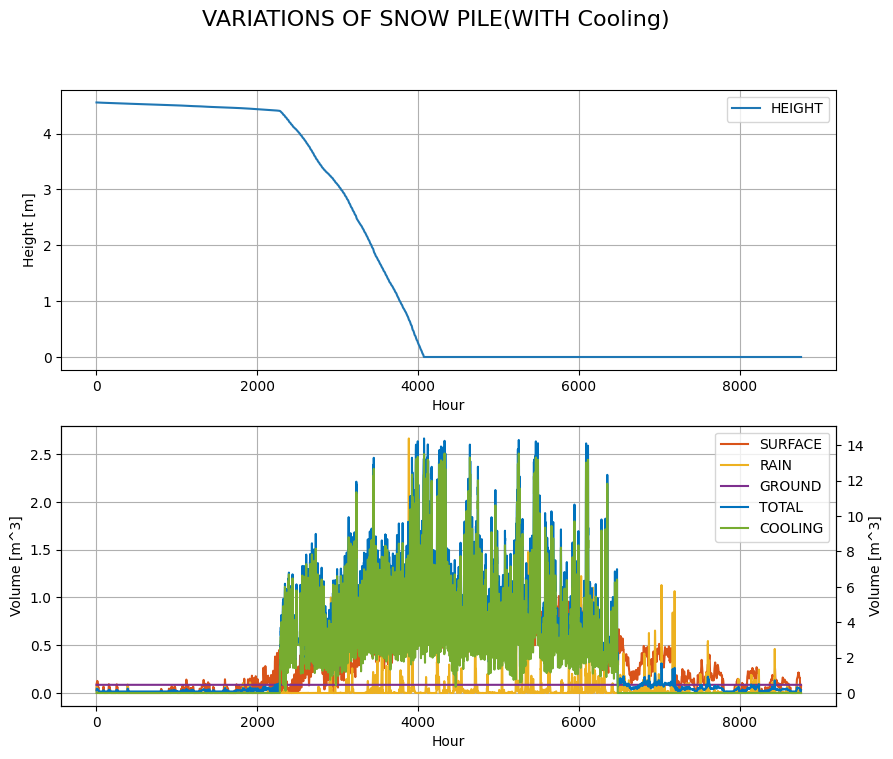

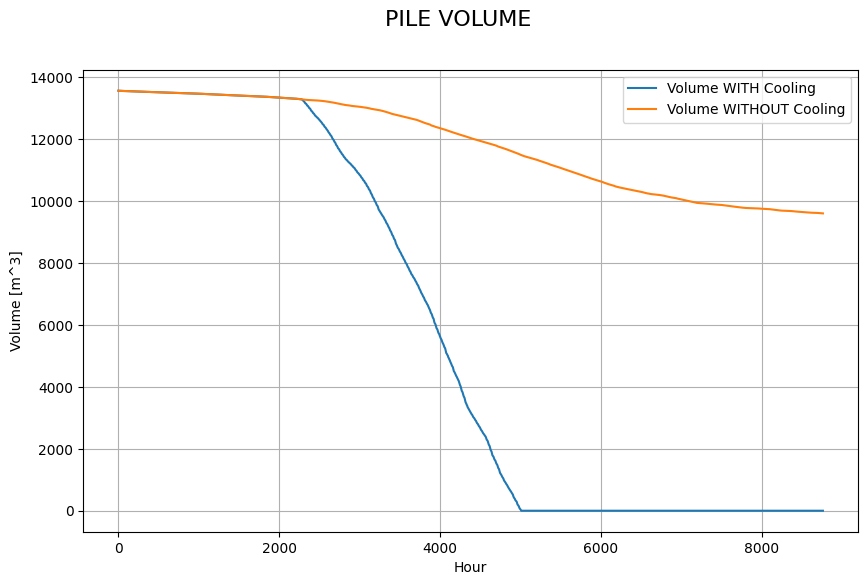

In [13]:
# Plot Figure 1
f1, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
f1.suptitle('VARIATIONS OF SNOW PILE(WITH Cooling)', fontsize=16)

time = np.arange(1, num_of_hrs + 1)
storeh_positive = storeh.copy()
storeh_positive[storeh_positive < 0] = 0
ax1.plot(time, storeh_positive) # Plot only positive height values
ax1.set_ylabel('Height [m]')
ax1.set_xlabel('Hour')
ax1.grid(True)
ax1.legend(['HEIGHT'])

# Plot Figure 2
data = Vf2.T
# Ensure all volume components are non-negative for plotting
data_positive = np.maximum(data, 0)

# 'SURFACE', 'RAIN', 'GROUND' on the primary y-axis
ax2.plot(time, data_positive[:, 2], color='#D95319', label='SURFACE')
ax2.plot(time, data_positive[:, 3], color='#EDB120', label='RAIN')
ax2.plot(time, data_positive[:, 4], color='#7E2F8E', label='GROUND')
ax2.set_ylabel('Volume [m^3]')
ax2.set_xlabel('Hour')
ax2.grid(True)

# Secondary y-axis for 'TOTAL' and 'COOLING'
ax2b = ax2.twinx()
ax2b.plot(time, data_positive[:, 0], color='#0072BD', label='TOTAL')
ax2b.plot(time, data_positive[:, 5], color='#77AC30', label='COOLING')
ax2b.set_ylabel('Volume [m^3]')

# Combine legends from both axes
lines, labels = ax2.get_legend_handles_labels()
lines2, labels2 = ax2b.get_legend_handles_labels()
ax2b.legend(lines + lines2, labels + labels2, loc='upper right')

# Plot Figure 3
f2, ax3 = plt.subplots(figsize=(10, 6))
f2.suptitle('PILE VOLUME', fontsize=16)

i = np.where(Vnew2 < 0)[0]
if len(i) == 0:
    ax3.plot(time, Vnew2, label='Volume WITH Cooling')
else:
    Vnew2TOP = Vnew2.copy()
    Vnew2TOP[i[0]:] = 0
    ax3.plot(time, Vnew2TOP, label='Volume WITH Cooling')

i = np.where(Vnew0 < 0)[0]
if len(i) == 0:
    ax3.plot(time, Vnew0, label='Volume WITHOUT Cooling')
else:
    Vnew0TOP = Vnew0.copy()
    Vnew0TOP[i[0]:] = 0
    ax3.plot(time, Vnew0TOP, '.', label='Volume WITHOUT Cooling')

ax3.set_ylabel('Volume [m^3]')
ax3.set_xlabel('Hour')
ax3.grid(True)
ax3.legend()

plt.show()

System level

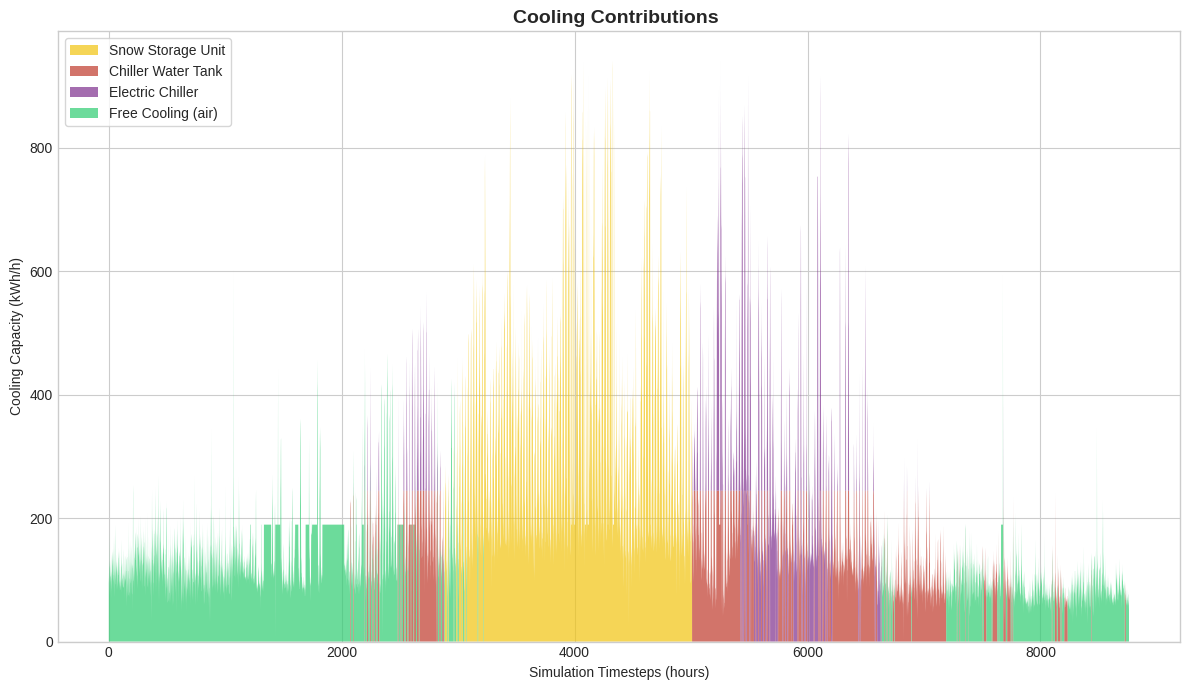

In [14]:
import matplotlib.pyplot as plt
import numpy as np

#Plot Figure 4
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 7))
time = np.arange(1, num_of_hrs + 1)

ax.stackplot(
    time,
    snow_used,
    tank_discharge,
    chiller_2load,
    air_cooling,
    labels=['Snow Storage Unit', 'Chiller Water Tank', 'Electric Chiller', 'Free Cooling (air)'],
    colors=['#F1C40F', '#C0392B', '#7E2F8E', '#2ECC71'],
    alpha=0.7
)

ax.set_title('Cooling Contributions ', fontsize=14, fontweight='bold')
ax.set_xlabel('Simulation Timesteps (hours)')
ax.set_ylabel('Cooling Capacity (kWh/h)')
ax.legend(loc='upper left', frameon=True)
ax.set_ylim(bottom=0)
ax.grid(True)

plt.tight_layout()
plt.show()